In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ffxiv_stats import Rate, Rotation
from matplotlib.ticker import FuncFormatter

from shared import mixture_distribution, pmf_std, relative_d2, thousands_formatter, set_custom_style

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

In [2]:
n_r = 15
n_rb = 8
n_rnb = 15 - n_rb

d_pp3 = relative_d2(360)
d_pp1 = relative_d2(100)
print("PP3:", d_pp3)
print("PP1:", d_pp1)

PP3: 16363
PP1: 4545


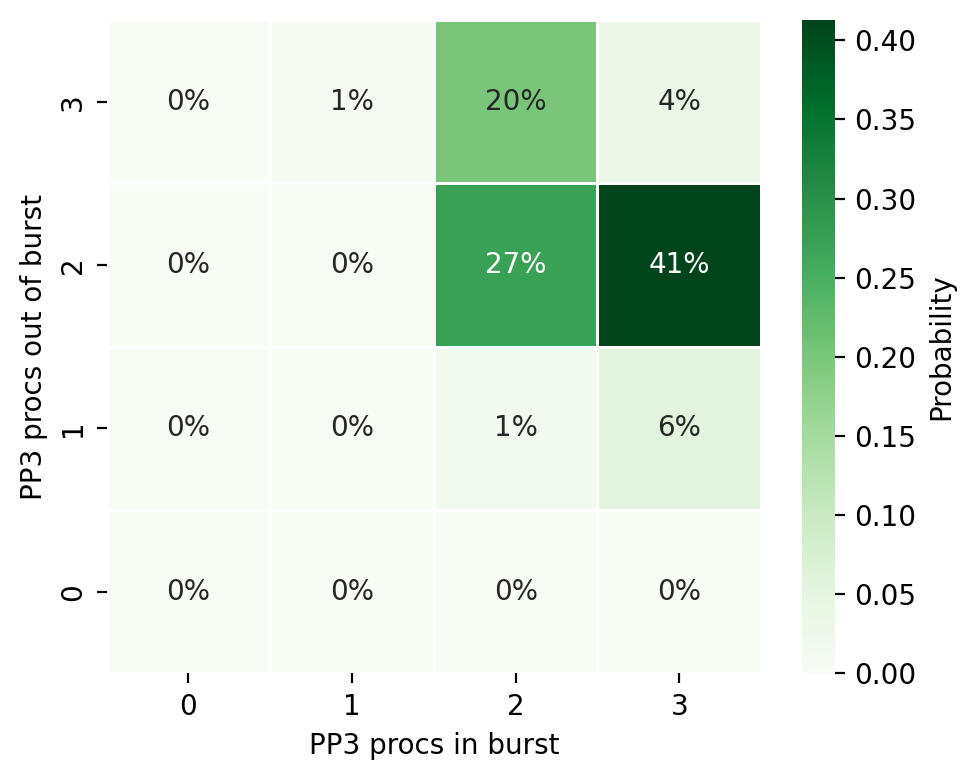

In [3]:
def joint_pp3_prob(
    k_burst: int,
    k_no_burst: int,
    n_rep_burst: int,
    n_repertoire_non_burst: int,
    p_repertoire: float = 0.8,
):
    total_prob = 0.0

    # Sum over all possible remainders r = 0,1,2
    for r in [0, 1, 2]:
        # 1) Burst-window part: sum over k_r_b that yield (i, r)
        sum_b = 0.0
        for k_b in range(n_rep_burst + 1):
            if ((k_b + 2) // 3 == k_burst) and ((k_b + 2) % 3 == r):
                # Binomial PMF at k_b
                prob_kb = (
                    math.comb(n_rep_burst, k_b)
                    * (p_repertoire**k_b)
                    * ((1 - p_repertoire) ** (n_rep_burst - k_b))
                )
                sum_b += prob_kb

        # 2) Non-burst-window part: sum over k_r_nb that yield j given remainder r
        sum_nb = 0.0
        for k_nb in range(n_repertoire_non_burst + 1):
            if (k_nb + r + 1) // 3 == k_no_burst:
                prob_knb = (
                    math.comb(n_repertoire_non_burst, k_nb)
                    * (p_repertoire**k_nb)
                    * ((1 - p_repertoire) ** (n_repertoire_non_burst - k_nb))
                )
                sum_nb += prob_knb

        # Multiply and add to the running total
        total_prob += sum_b * sum_nb

    return total_prob


pp3_probabilities = np.array(
    [[joint_pp3_prob(k_b, k_nb, n_rb, n_rnb) for k_b in range(4)] for k_nb in range(4)]
)

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=200)
sns.heatmap(
    pp3_probabilities[::-1],
    cmap="Greens",
    ax=ax,
    cbar_kws={"label": "Probability"},
    annot=True,
    fmt=".0%",
    linewidths=1.0,
)
ax.set_xlabel("PP3 procs in burst")
ax.set_ylabel("PP3 procs out of burst")
ax.set_yticklabels([3, 2, 1, 0])
plt.tight_layout()
plt.savefig("../tex/img/wm-joint.png")
plt.show()

In [4]:
def make_pp3_burst_record(n, p, l_c):
    return {
        "n": n,
        "d2": d_pp3,
        "action_name": "Pitch Perfect 3-burst",
        "base_action": "Pitch Perfect",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": l_c,
        "buffs": 1.173,
        "is_dot": False,
    }


def make_pp3_no_burst_record(n, p, l_c):
    return {
        "n": n,
        "d2": d_pp3,
        "action_name": "Pitch Perfect 3-non-burst",
        "base_action": "Pitch Perfect",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": l_c,
        "buffs": 1.0,
        "is_dot": False,
    }


def make_pp1_no_burst_record(p, l_c):
    return {
        "n": 1,
        "d2": d_pp1,
        "action_name": "Pitch Perfect 1-non-burst",
        "base_action": "Pitch Perfect",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": l_c,
        "buffs": 1.0,
        "is_dot": False,
    }


r = Rate(3000, 2000)
print(r.p)
print(r.l_c)
rotations = []
w = []
for i in range(4):
    for j in range(4):
        records = []

        # Ignore when there are no usages, ffxiv_stats doesn't like that
        if i > 0:
            records.append(make_pp3_burst_record(i, r.get_p(0.02, 0.2), r.l_c))
        if j > 0:
            records.append(make_pp3_no_burst_record(j, r.get_p(0.02), r.l_c))

        # Final PP1 leftover, except for i = 3, j = 3
        if (i + j > 0) & (i + j < 6):
            records.append(make_pp1_no_burst_record(r.get_p(0.02), r.l_c))

        if len(records) > 0:
            print(i, j)
            rotation_df = pd.DataFrame(records)
            rotations.append(Rotation(rotation_df, 1, 1, 1, 1, 1))
            w.append(pp3_probabilities[i, j])


[0.52632 0.16168 0.23868 0.07332]
1585.0
0 1
0 2
0 3
1 0
1 1
1 2
1 3
2 0
2 1
2 2
2 3
3 0
3 1
3 2
3 3


sigma percent change: 

 41.17949629636307


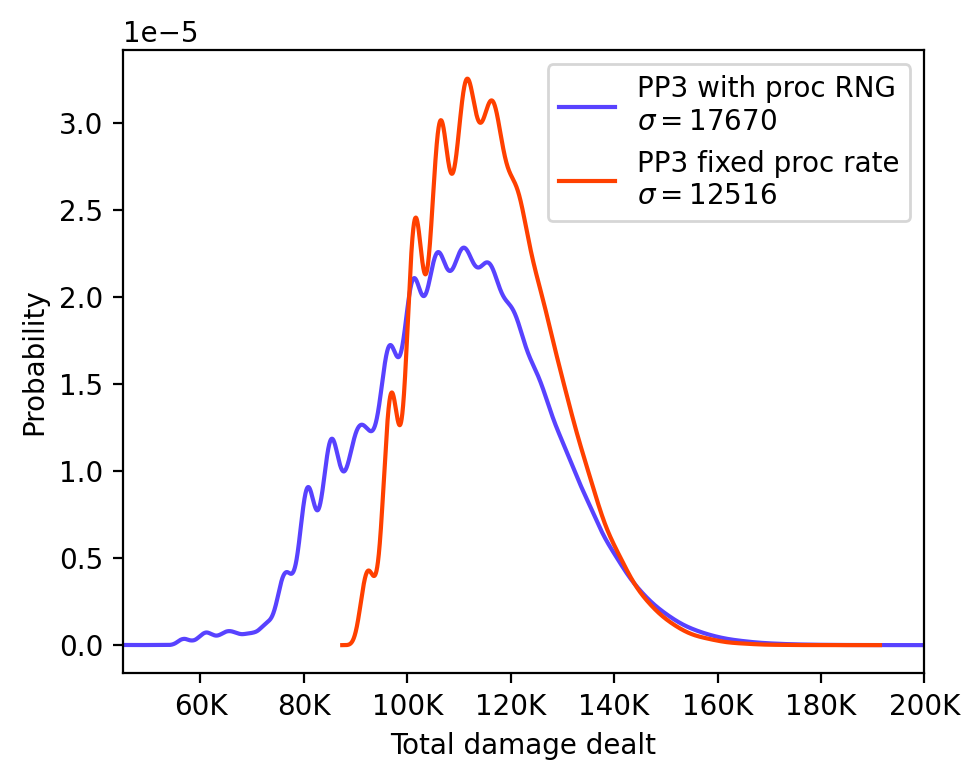

In [5]:
mixture_pmf, mixture_supp = mixture_distribution(rotations, w)

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=200)

proc_std = pmf_std(mixture_supp, mixture_pmf)
mode_std = rotations[-5].rotation_std
print("sigma percent change: ", 100 * (proc_std - mode_std) / mode_std)

ax.plot(
    mixture_supp, mixture_pmf, label="PP3 with proc RNG\n" + rf"$\sigma={proc_std:.0f}$"
)
rotations[-5].plot_rotation_distribution(
    ax, label="PP3 fixed proc rate\n" + rf"$\sigma={mode_std:.0f}$"
)

ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))

ax.legend()
ax.set_xlabel("Total damage dealt")
ax.set_ylabel("Probability")
ax.set_xlim([45000, 200000])
plt.tight_layout()
plt.savefig("../tex/img/wm-dmg-distribution.png")
plt.show()

## Comparison to random sampling

Also see how the final leftover PP stack out of burst varies.

In [6]:
test = np.random.binomial(1, 0.8, size=(10000000, n_r))

In [7]:
buff_pp = (test[:, 0:n_rb].sum(axis=1) + 2) // 3
buff_carryover = (test[:, 0:n_rb].sum(axis=1) + 2) % 3

buff_pp, buff_carryover
print("buff_pp:", buff_pp)
print("buff_re:", buff_carryover)

buff_pp: [3 3 2 ... 2 3 3]
buff_re: [1 1 2 ... 1 1 0]


In [8]:
non_buff_pp = (test[:, n_rb:].sum(axis=1) + 1 + buff_carryover) // 3
non_buff_carryover = (test[:, n_rb:].sum(axis=1) + 1 + buff_carryover) % 3

print("non_buff_pp:", non_buff_pp)
print("non_buff_re:", non_buff_carryover)

non_buff_pp: [2 2 2 ... 2 2 1]
non_buff_re: [1 2 2 ... 2 0 2]


<Axes: >

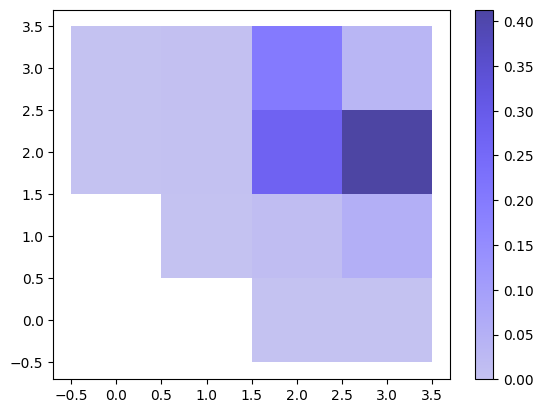

In [9]:
sns.histplot(x=buff_pp, y=non_buff_pp, discrete=True, stat="probability", cbar=True)

0.3289295
0.3373771
0.3336934


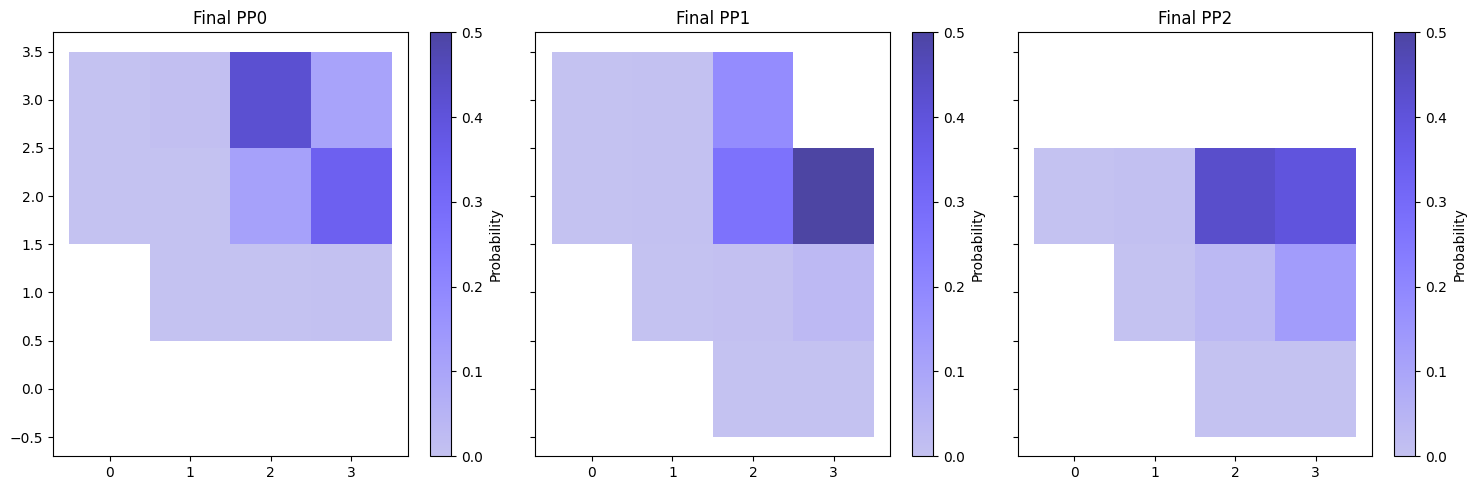

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for a in range(3):
    hue = np.where(non_buff_carryover == a)[0]
    print(hue.size / non_buff_carryover.size)
    plot_buff_pp = buff_pp[hue]
    plot_non_buff_pp = non_buff_pp[hue]

    if plot_buff_pp.size > 0 and plot_non_buff_pp.size > 0:
        sns.histplot(
            x=plot_buff_pp,
            y=plot_non_buff_pp,
            discrete=True,
            ax=ax[a],
            stat="probability",
            cbar=True,
            vmin=0,
            vmax=0.5,
            cbar_kws={"label": "Probability"},
        )

    ax[a].set_title(f"Final PP{a}")

plt.tight_layout()